Imports and dataset path

In [1]:
import xml.etree.ElementTree as ET
from pathlib import Path
from collections import Counter

import cv2
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

# Run Jupyter from your project root
candidates = [
    Path("data/NEU-DET"),
    Path("../data/NEU-DET")
]

DATASET_PATH = next(
    (p for p in candidates if p.exists()),
    None
)

if DATASET_PATH is None:
    raise FileNotFoundError("NEU-DET dataset folder not found.")

CLASS_NAMES = [
    "crazing",
    "inclusion",
    "patches",
    "pitted_surface",
    "rolled-in_scale",
    "scratches"
]

print("Dataset:", DATASET_PATH.resolve())

Dataset: D:\Industrial Surface Defect Detection and Classification Using CNN,Transfer Learning and Tensorflow\data\NEU-DET


Load image information

In [2]:
image_records = []

for split in ["train", "validation"]:

    image_root = DATASET_PATH / split / "images"

    for image_path in image_root.rglob("*.jpg"):

        image = cv2.imread(str(image_path))

        if image is None:
            continue

        height, width = image.shape[:2]

        image_records.append({
            "split": split,
            "image": image_path.name,
            "image_path": str(image_path),
            "class_folder": image_path.parent.name,
            "height": height,
            "width": width,
            "channels": image.shape[2] if image.ndim == 3 else 1
        })

image_df = pd.DataFrame(image_records)

print("Total readable images:", len(image_df))
display(image_df.head())

Total readable images: 1800


,split,image,image_path,class_folder,height,width,channels
0,train,crazing_1.jpg,..\data\NEU-DET\train\images\crazing\crazing_1...,crazing,200,200,3
1,train,crazing_10.jpg,..\data\NEU-DET\train\images\crazing\crazing_1...,crazing,200,200,3
2,train,crazing_100.jpg,..\data\NEU-DET\train\images\crazing\crazing_1...,crazing,200,200,3
3,train,crazing_101.jpg,..\data\NEU-DET\train\images\crazing\crazing_1...,crazing,200,200,3
4,train,crazing_102.jpg,..\data\NEU-DET\train\images\crazing\crazing_1...,crazing,200,200,3


Load all XML annotations

In [3]:
annotation_records = []

for split in ["train", "validation"]:

    annotation_root = DATASET_PATH / split / "annotations"

    for xml_path in annotation_root.glob("*.xml"):

        root = ET.parse(xml_path).getroot()

        filename = root.findtext("filename")

        for obj in root.findall("object"):

            class_name = obj.findtext("name")
            box = obj.find("bndbox")

            if box is None:
                continue

            xmin = float(box.findtext("xmin"))
            ymin = float(box.findtext("ymin"))
            xmax = float(box.findtext("xmax"))
            ymax = float(box.findtext("ymax"))

            annotation_records.append({
                "split": split,
                "image": filename,
                "class": class_name,
                "xmin": xmin,
                "ymin": ymin,
                "xmax": xmax,
                "ymax": ymax,
                "xml_file": xml_path.name
            })

annotation_df = pd.DataFrame(annotation_records)

print("Total annotations:", len(annotation_df))
display(annotation_df.head())

Total annotations: 4189


,split,image,class,xmin,ymin,xmax,ymax,xml_file
0,train,crazing_1.jpg,crazing,2.0,2.0,193.0,194.0,crazing_1.xml
1,train,crazing_10.jpg,crazing,60.0,20.0,194.0,69.0,crazing_10.xml
2,train,crazing_10.jpg,crazing,9.0,84.0,197.0,198.0,crazing_10.xml
3,train,crazing_100.jpg,crazing,1.0,10.0,108.0,121.0,crazing_100.xml
4,train,crazing_100.jpg,crazing,35.0,1.0,200.0,83.0,crazing_100.xml


Image distribution by class

split,train,validation
class_folder,,
crazing,240,60
inclusion,240,60
patches,240,60
pitted_surface,240,60
rolled-in_scale,240,60
scratches,240,60


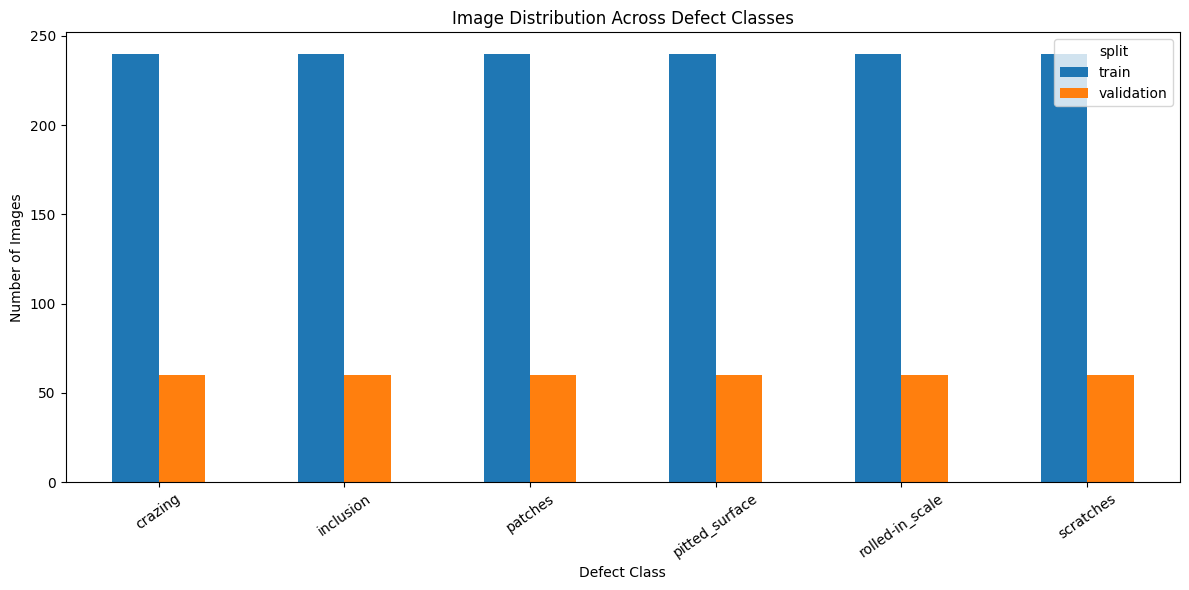

In [4]:
class_distribution = (
    image_df.groupby(["class_folder", "split"])
    .size()
    .unstack(fill_value=0)
)

display(class_distribution)

class_distribution.plot(
    kind="bar",
    figsize=(12, 6)
)

plt.title("Image Distribution Across Defect Classes")
plt.xlabel("Defect Class")
plt.ylabel("Number of Images")
plt.xticks(rotation=35)
plt.tight_layout()
plt.show()

Annotation distribution by defect

split,train,validation
class,,
crazing,524,165
inclusion,852,159
patches,688,193
pitted_surface,345,87
rolled-in_scale,496,132
scratches,427,121


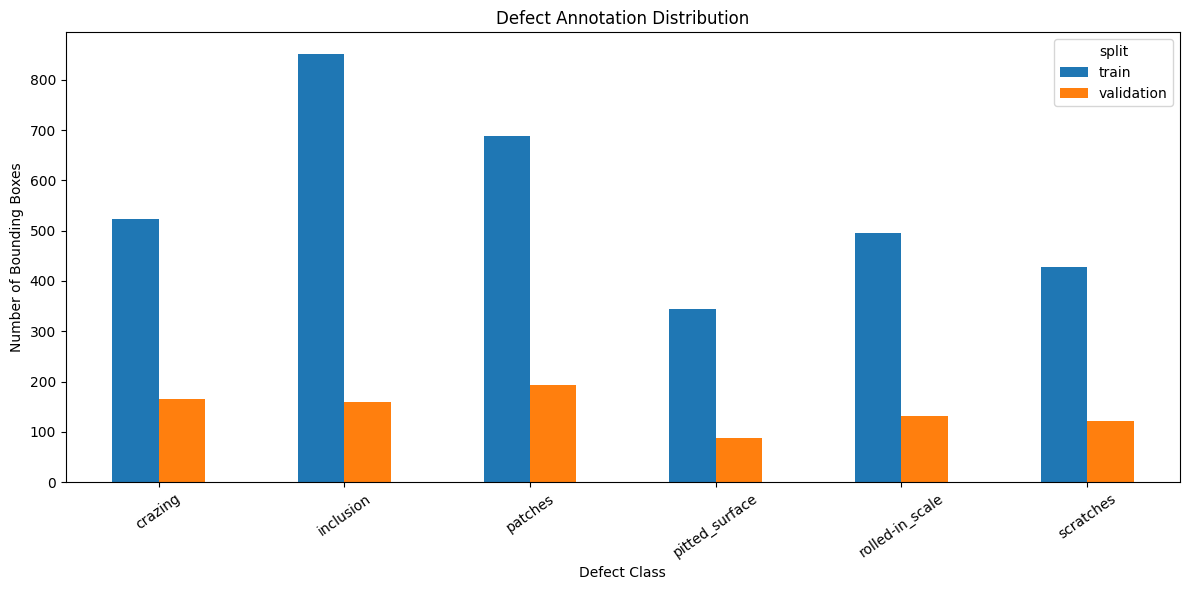

In [5]:
annotation_distribution = (
    annotation_df.groupby(["class", "split"])
    .size()
    .unstack(fill_value=0)
)

display(annotation_distribution)

annotation_distribution.plot(
    kind="bar",
    figsize=(12, 6)
)

plt.title("Defect Annotation Distribution")
plt.xlabel("Defect Class")
plt.ylabel("Number of Bounding Boxes")
plt.xticks(rotation=35)
plt.tight_layout()
plt.show()

Bounding-box dimensions and area

In [6]:
bbox_df = annotation_df.copy()

bbox_df["box_width"] = bbox_df["xmax"] - bbox_df["xmin"]
bbox_df["box_height"] = bbox_df["ymax"] - bbox_df["ymin"]

bbox_df["box_area"] = (
    bbox_df["box_width"] * bbox_df["box_height"]
)

bbox_df["aspect_ratio"] = (
    bbox_df["box_width"] / bbox_df["box_height"]
)

bbox_df["area_percentage"] = (
    bbox_df["box_area"] / (200 * 200) * 100
)

display(
    bbox_df[
        ["class", "box_width", "box_height",
         "box_area", "aspect_ratio", "area_percentage"]
    ].describe()
)

,box_width,box_height,box_area,aspect_ratio,area_percentage
count,4189.000000,4189.000000,4189.000000,4189.000000,4189.000000
mean,71.401528,95.009310,6980.188350,1.132570,17.450471
std,52.042753,56.538013,7546.098134,1.518868,18.865245
min,8.000000,9.000000,108.000000,0.045455,0.270000
25%,30.000000,50.000000,2052.000000,0.372093,5.130000
50%,55.000000,77.000000,4715.000000,0.681818,11.787500
75%,100.000000,136.000000,8763.000000,1.255319,21.907500
max,199.000000,199.000000,39601.000000,18.000000,99.002500


Visualize bounding-box sizes

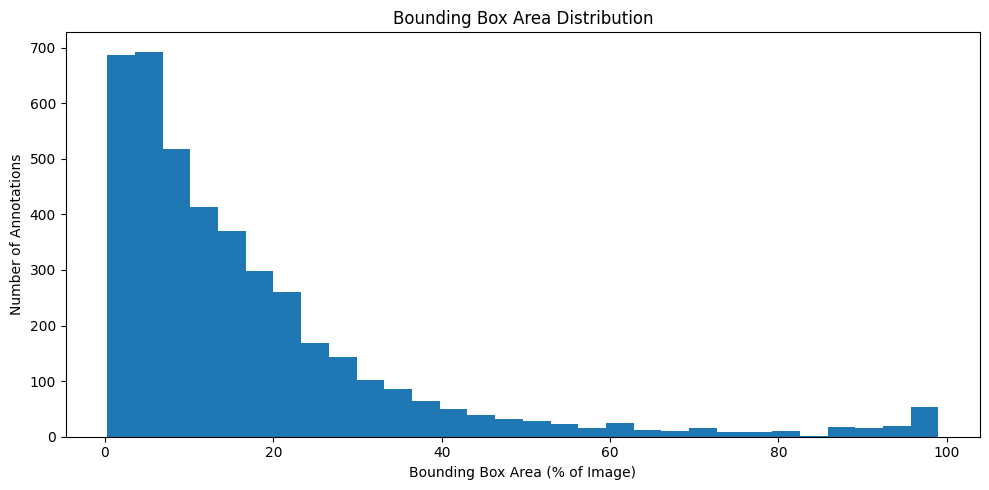

In [7]:
plt.figure(figsize=(10, 5))

plt.hist(
    bbox_df["area_percentage"],
    bins=30
)

plt.title("Bounding Box Area Distribution")
plt.xlabel("Bounding Box Area (% of Image)")
plt.ylabel("Number of Annotations")
plt.tight_layout()
plt.show()

<Figure size 1000x500 with 0 Axes>

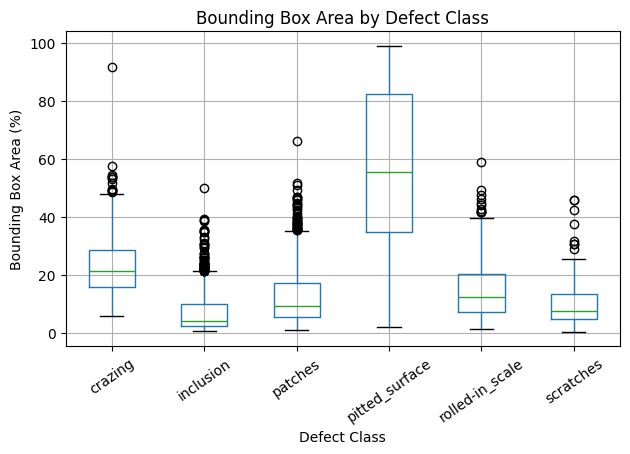

In [8]:
plt.figure(figsize=(10, 5))

bbox_df.boxplot(
    column="area_percentage",
    by="class",
    rot=35
)

plt.title("Bounding Box Area by Defect Class")
plt.suptitle("")
plt.xlabel("Defect Class")
plt.ylabel("Bounding Box Area (%)")
plt.tight_layout()
plt.show()

Objects per image

In [9]:
objects_per_image = (
    annotation_df.groupby(["split", "image"])
    .size()
    .reset_index(name="object_count")
)

print("Objects per image:")
display(objects_per_image["object_count"].describe())

print("\nImages with multiple annotated objects:")
display(
    objects_per_image[
        objects_per_image["object_count"] > 1
    ].head(20)
)

Objects per image:


count    1800.000000
mean        2.327222
std         1.251184
min         1.000000
25%         1.000000
50%         2.000000
75%         3.000000
max         9.000000
Name: object_count, dtype: float64


Images with multiple annotated objects:


,split,image,object_count
1,train,crazing_10.jpg,2
2,train,crazing_100.jpg,4
4,train,crazing_102.jpg,2
5,train,crazing_103.jpg,3
6,train,crazing_104.jpg,4
7,train,crazing_105.jpg,4
8,train,crazing_106.jpg,3
9,train,crazing_107.jpg,3
10,train,crazing_108.jpg,2
11,train,crazing_109.jpg,3


Check image and XML matching

In [10]:
image_keys = set(
    zip(image_df["split"], image_df["image"])
)

annotation_keys = set(
    zip(annotation_df["split"], annotation_df["image"])
)

images_without_annotations = image_keys - annotation_keys
annotations_without_images = annotation_keys - image_keys

print("Images without XML annotations:", len(images_without_annotations))
print("XML annotations without images:", len(annotations_without_images))

print("\nExamples:")
print(list(images_without_annotations)[:10])
print(list(annotations_without_images)[:10])

Images without XML annotations: 175
XML annotations without images: 175

Examples:
[('train', 'pitted_surface_23.jpg'), ('train', 'pitted_surface_47.jpg'), ('train', 'pitted_surface_139.jpg'), ('train', 'pitted_surface_121.jpg'), ('train', 'pitted_surface_19.jpg'), ('train', 'patches_29.jpg'), ('train', 'pitted_surface_4.jpg'), ('train', 'pitted_surface_64.jpg'), ('train', 'pitted_surface_133.jpg'), ('train', 'pitted_surface_52.jpg')]
[('train', 'pitted_surface_32'), ('train', 'patches_24'), ('train', 'pitted_surface_82'), ('train', 'pitted_surface_119'), ('train', 'pitted_surface_24'), ('train', 'patches_203'), ('train', 'patches_12'), ('train', 'pitted_surface_169'), ('train', 'pitted_surface_120'), ('train', 'pitted_surface_127')]


Check class-name consistency

In [11]:
print("Expected classes:")
print(CLASS_NAMES)

print("\nClasses found in XML:")
print(sorted(annotation_df["class"].dropna().unique()))

unknown_classes = set(annotation_df["class"].dropna()) - set(CLASS_NAMES)

print("\nUnknown classes:", unknown_classes)

Expected classes:
['crazing', 'inclusion', 'patches', 'pitted_surface', 'rolled-in_scale', 'scratches']

Classes found in XML:
['crazing', 'inclusion', 'patches', 'pitted_surface', 'rolled-in_scale', 'scratches']

Unknown classes: set()


Generate final EDA summary

In [12]:
print("=" * 55)
print("NEU-DET EXPLORATORY DATA ANALYSIS SUMMARY")
print("=" * 55)

print("Total readable images:", len(image_df))
print("Total annotations:", len(annotation_df))

print("\nImages by split:")
print(image_df["split"].value_counts())

print("\nAnnotations by split:")
print(annotation_df["split"].value_counts())

print("\nImages by class:")
print(image_df["class_folder"].value_counts())

print("\nAnnotations by class:")
print(annotation_df["class"].value_counts())

print("\nInvalid bounding boxes:", (
    (bbox_df["box_width"] <= 0) |
    (bbox_df["box_height"] <= 0)
).sum())

print("\nUnknown classes:", len(unknown_classes))

print("\nImages without annotations:", len(images_without_annotations))
print("Annotations without images:", len(annotations_without_images))

print("=" * 55)

NEU-DET EXPLORATORY DATA ANALYSIS SUMMARY
Total readable images: 1800
Total annotations: 4189

Images by split:
split
train         1440
validation     360
Name: count, dtype: int64

Annotations by split:
split
train         3332
validation     857
Name: count, dtype: int64

Images by class:
class_folder
crazing            300
inclusion          300
patches            300
pitted_surface     300
rolled-in_scale    300
scratches          300
Name: count, dtype: int64

Annotations by class:
class
inclusion          1011
patches             881
crazing             689
rolled-in_scale     628
scratches           548
pitted_surface      432
Name: count, dtype: int64

Invalid bounding boxes: 0

Unknown classes: 0

Images without annotations: 175
Annotations without images: 175
